In [1]:
# ============================================================
# 1. IMPORTACIÓN DE BIBLIOTECAS
# ============================================================

import sys
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.naive_bayes import GaussianNB
from sklearn.neural_network import MLPClassifier
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report,
    roc_curve, auc, ConfusionMatrixDisplay,
    precision_recall_curve, average_precision_score
)
from IPython.display import display as mostrar_tabla

print("Bibliotecas importadas correctamente")


Bibliotecas importadas correctamente


In [2]:
# ============================================================
# 2. CONFIGURACIÓN DEL PROYECTO Y RUTAS CENTRALIZADAS
# ============================================================

CURRENT_DIR = Path.cwd().resolve()
ROOT_DIR = None
for directory in [CURRENT_DIR, *CURRENT_DIR.parents]:
    if (directory / "config.py").is_file():
        ROOT_DIR = directory
        break

if ROOT_DIR is None:
    raise FileNotFoundError("No se encontró config.py en el proyecto.")

if str(ROOT_DIR) not in sys.path:
    sys.path.insert(0, str(ROOT_DIR))

from config import (
    PROCESSED_DATA_DIR, MODELS_DIR, REPORTS_DIR,
    FIGURES_DIR, RANDOM_STATE
)

for directory in [PROCESSED_DATA_DIR, MODELS_DIR, REPORTS_DIR, FIGURES_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

print("Configuración cargada desde:", ROOT_DIR)


Configuración cargada desde: C:\Users\diego\Desktop\proyecto_data_scients


In [3]:
# ============================================================
# 3. CARGAR LAS PARTICIONES PROCESADAS
# ============================================================

# La división se realiza únicamente en 02_Preprocesamiento.ipynb.
# Este notebook reutiliza las particiones guardadas en data/processed.

def cargar_caracteristicas(nombre_archivo):
    ruta = PROCESSED_DATA_DIR / nombre_archivo
    if not ruta.is_file():
        raise FileNotFoundError(f"No se encontró el archivo: {ruta}")
    return pd.read_csv(ruta)


def cargar_etiquetas(nombre_archivo):
    ruta = PROCESSED_DATA_DIR / nombre_archivo
    if not ruta.is_file():
        raise FileNotFoundError(f"No se encontró el archivo: {ruta}")
    return pd.read_csv(ruta).squeeze("columns").astype("int64")

X_train = cargar_caracteristicas("X_train.csv")
X_val = cargar_caracteristicas("X_val.csv")
X_test = cargar_caracteristicas("X_test.csv")

y_train = cargar_etiquetas("y_train.csv")
y_val = cargar_etiquetas("y_val.csv")
y_test = cargar_etiquetas("y_test.csv")

test_metadata_path = PROCESSED_DATA_DIR / "test_metadata.csv"
if not test_metadata_path.is_file():
    raise FileNotFoundError(
        "No se encontró test_metadata.csv. Ejecuta primero 02_Preprocesamiento.ipynb."
    )
test_metadata = pd.read_csv(test_metadata_path)

# Comprobaciones de integridad.
if not (len(X_train) == len(y_train)
        and len(X_val) == len(y_val)
        and len(X_test) == len(y_test) == len(test_metadata)):
    raise ValueError("Las dimensiones de las particiones no coinciden.")

if not (X_train.columns.equals(X_val.columns)
        and X_train.columns.equals(X_test.columns)):
    raise ValueError("Las columnas de las particiones no coinciden.")

if set(pd.unique(y_train)) - {0, 1}:
    raise ValueError("y_train contiene etiquetas distintas de 0 y 1.")

metadata_labels = test_metadata["Diagnosis"].map({"B": 0, "M": 1})
if metadata_labels.isna().any() or not np.array_equal(metadata_labels.to_numpy(), y_test.to_numpy()):
    raise ValueError("Los metadatos no coinciden con las etiquetas de prueba.")

print("Particiones procesadas y metadatos cargados correctamente")
print("Entrenamiento:", X_train.shape, "| y:", y_train.shape)
print("Validación:", X_val.shape, "| y:", y_val.shape)
print("Prueba:", X_test.shape, "| y:", y_test.shape)


Particiones procesadas y metadatos cargados correctamente
Entrenamiento: (398, 30) | y: (398,)
Validación: (85, 30) | y: (85,)
Prueba: (86, 30) | y: (86,)


In [4]:

# ============================================================
# 5. MODELO DE REFERENCIA: REGRESIÓN LOGÍSTICA
# ============================================================

# Crear un pipeline con escalado y regresión logística
baseline_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        max_iter=2000,
        random_state=RANDOM_STATE
    ))
])

print("Modelo de referencia creado correctamente")


Modelo de referencia creado correctamente


In [5]:

# ============================================================
# 6. VALIDACIÓN CRUZADA DEL MODELO DE REFERENCIA
# ============================================================

# Configurar validación cruzada estratificada
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

# Métricas que vamos a evaluar
scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}

# Ejecutar validación cruzada solamente con entrenamiento
cv_results = cross_validate(
    baseline_model,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    return_train_score=False
)

# Mostrar promedio y desviación estándar
print("RESULTADOS DE VALIDACIÓN CRUZADA")
print("--------------------------------")

for metric in scoring:
    scores = cv_results[f"test_{metric}"]

    print(
        f"{metric.upper():10} "
        f"Media: {scores.mean():.4f} | "
        f"Desviación estándar: {scores.std():.4f}"
    )


RESULTADOS DE VALIDACIÓN CRUZADA
--------------------------------
ACCURACY   Media: 0.9824 | Desviación estándar: 0.0062
PRECISION  Media: 1.0000 | Desviación estándar: 0.0000
RECALL     Media: 0.9526 | Desviación estándar: 0.0167
F1         Media: 0.9757 | Desviación estándar: 0.0088
ROC_AUC    Media: 0.9926 | Desviación estándar: 0.0064


In [6]:

# ============================================================
# 7. ENTRENAMIENTO DEL MODELO DE REFERENCIA
# ============================================================

baseline_model.fit(X_train, y_train)

# Obtener predicciones
y_val_pred = baseline_model.predict(X_val)

# Obtener probabilidades de la clase positiva (maligno)
y_val_proba = baseline_model.predict_proba(X_val)[:, 1]


# ============================================================
# 8. EVALUACIÓN EN VALIDACIÓN
# ============================================================

print("RESULTADOS EN EL CONJUNTO DE VALIDACIÓN")
print("---------------------------------------")

print("Accuracy:", accuracy_score(y_val, y_val_pred))

print("Precision:", precision_score(y_val, y_val_pred))

print("Recall:", recall_score(y_val, y_val_pred))

print("F1:", f1_score(y_val, y_val_pred))

print("ROC-AUC:", roc_auc_score(y_val, y_val_proba))


# ============================================================
# 9. REPORTE DE CLASIFICACIÓN
# ============================================================

print("\nREPORTE DE CLASIFICACIÓN")

print(
    classification_report(
        y_val,
        y_val_pred,
        target_names=["Benigno", "Maligno"],
        zero_division=0
    )
)


# ============================================================
# 10. MATRIZ DE CONFUSIÓN
# ============================================================

print("MATRIZ DE CONFUSIÓN")

cm = confusion_matrix(y_val, y_val_pred)

mostrar_tabla(
    pd.DataFrame(
        cm,
        index=["Real Benigno", "Real Maligno"],
        columns=["Predicho Benigno", "Predicho Maligno"]
    )
)


RESULTADOS EN EL CONJUNTO DE VALIDACIÓN
---------------------------------------
Accuracy: 0.9647058823529412
Precision: 1.0
Recall: 0.90625
F1: 0.9508196721311475
ROC-AUC: 0.9964622641509434

REPORTE DE CLASIFICACIÓN
              precision    recall  f1-score   support

     Benigno       0.95      1.00      0.97        53
     Maligno       1.00      0.91      0.95        32

    accuracy                           0.96        85
   macro avg       0.97      0.95      0.96        85
weighted avg       0.97      0.96      0.96        85

MATRIZ DE CONFUSIÓN


,Predicho Benigno,Predicho Maligno
Real Benigno,53,0
Real Maligno,3,29


In [7]:

# ============================================================
# 11. MODELO GAUSSIAN NAIVE BAYES
# ============================================================

# Crear pipeline
nb_pipeline = Pipeline([
    ("classifier", GaussianNB())
])


# ============================================================
# 12. ESPACIO DE BÚSQUEDA DE HIPERPARÁMETROS
# ============================================================

param_grid_nb = {
    "classifier__var_smoothing": np.logspace(-12, -6, 7)
}

# Mostrar valores que vamos a probar
print("Valores de var_smoothing:")
print(param_grid_nb["classifier__var_smoothing"])


Valores de var_smoothing:
[1.e-12 1.e-11 1.e-10 1.e-09 1.e-08 1.e-07 1.e-06]


In [8]:

# ============================================================
# 13. BÚSQUEDA DE HIPERPARÁMETROS
# ============================================================

scoring_nb = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}

nb_search = GridSearchCV(
    estimator=nb_pipeline,
    param_grid=param_grid_nb,
    scoring=scoring_nb,
    refit="f1",
    cv=cv,
    n_jobs=-1,
    return_train_score=False
)

# Entrenar y buscar la mejor configuración
nb_search.fit(X_train, y_train)


# ============================================================
# 14. MEJOR CONFIGURACIÓN ENCONTRADA
# ============================================================

print("MEJORES HIPERPARÁMETROS:")
print(nb_search.best_params_)

print("\nMEJOR F1 EN VALIDACIÓN CRUZADA:")
print(round(nb_search.best_score_, 4))


# ============================================================
# 15. RESULTADOS DE VALIDACIÓN CRUZADA
# ============================================================

best_index = nb_search.best_index_

print("\nRESULTADOS DE VALIDACIÓN CRUZADA")
print("--------------------------------")

for metric in scoring_nb:

    mean_score = nb_search.cv_results_[
        f"mean_test_{metric}"
    ][best_index]

    std_score = nb_search.cv_results_[
        f"std_test_{metric}"
    ][best_index]

    print(
        f"{metric.upper():10} "
        f"Media: {mean_score:.4f} | "
        f"Desviación estándar: {std_score:.4f}"
    )


MEJORES HIPERPARÁMETROS:
{'classifier__var_smoothing': np.float64(1e-09)}

MEJOR F1 EN VALIDACIÓN CRUZADA:
0.9171

RESULTADOS DE VALIDACIÓN CRUZADA
--------------------------------
ACCURACY   Media: 0.9396 | Desviación estándar: 0.0344
PRECISION  Media: 0.9319 | Desviación estándar: 0.0562
RECALL     Media: 0.9048 | Desviación estándar: 0.0597
F1         Media: 0.9171 | Desviación estándar: 0.0489
ROC_AUC    Media: 0.9857 | Desviación estándar: 0.0085


In [9]:

# ============================================================
# 16. PREDICCIONES EN VALIDACIÓN
# ============================================================
nb_model = nb_search.best_estimator_
y_val_pred_nb = nb_model.predict(X_val)

# Obtener probabilidades de la clase maligna
y_val_proba_nb = nb_model.predict_proba(X_val)[:, 1]



In [10]:
# ============================================================
# 17. MÉTRICAS DE EVALUACIÓN
# ============================================================

nb_val_metrics = {
    "Accuracy": accuracy_score(y_val, y_val_pred_nb),
    "Precision": precision_score(y_val, y_val_pred_nb),
    "Recall": recall_score(y_val, y_val_pred_nb),
    "F1": f1_score(y_val, y_val_pred_nb),
    "ROC-AUC": roc_auc_score(y_val, y_val_proba_nb)
}

print("RESULTADOS GAUSSIAN NAIVE BAYES")
print("--------------------------------")

for metric, value in nb_val_metrics.items():
    print(f"{metric:10}: {value:.4f}")


RESULTADOS GAUSSIAN NAIVE BAYES
--------------------------------
Accuracy  : 0.9294
Precision : 0.9643
Recall    : 0.8438
F1        : 0.9000
ROC-AUC   : 0.9900


In [11]:
# ============================================================
# 18. REPORTE DE CLASIFICACIÓN
# ============================================================

print("\nREPORTE DE CLASIFICACIÓN")

print(
    classification_report(
        y_val,
        y_val_pred_nb,
        target_names=["Benigno", "Maligno"],
        zero_division=0
    )
)


REPORTE DE CLASIFICACIÓN
              precision    recall  f1-score   support

     Benigno       0.91      0.98      0.95        53
     Maligno       0.96      0.84      0.90        32

    accuracy                           0.93        85
   macro avg       0.94      0.91      0.92        85
weighted avg       0.93      0.93      0.93        85



In [12]:
# ============================================================
# 19. MATRIZ DE CONFUSIÓN
# ============================================================

cm_nb = confusion_matrix(y_val, y_val_pred_nb)

print("MATRIZ DE CONFUSIÓN")

mostrar_tabla(
    pd.DataFrame(
        cm_nb,
        index=["Real Benigno", "Real Maligno"],
        columns=["Predicho Benigno", "Predicho Maligno"]
    )
)


MATRIZ DE CONFUSIÓN


,Predicho Benigno,Predicho Maligno
Real Benigno,52,1
Real Maligno,5,27


In [13]:
# ============================================================
# 20. MODELO SVM
# ============================================================

svm_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", SVC())
])

print("Pipeline SVM creado correctamente")

Pipeline SVM creado correctamente


In [14]:
# ============================================================
# 21. ESPACIO DE BÚSQUEDA DE HIPERPARÁMETROS
# ============================================================

param_grid_svm = [

    # Kernel lineal
    {
        "classifier__kernel": ["linear"],
        "classifier__C": [0.1, 1, 10, 100]
    },

    # Kernel RBF
    {
        "classifier__kernel": ["rbf"],
        "classifier__C": [0.1, 1, 10, 100],
        "classifier__gamma": [
            "scale",
            "auto",
            0.001,
            0.01,
            0.1
        ]
    }
]

print("Configuraciones de búsqueda:")
mostrar_tabla(pd.DataFrame(param_grid_svm))

Configuraciones de búsqueda:


,classifier__kernel,classifier__C,classifier__gamma
0,[linear],"[0.1, 1, 10, 100]",NaN
1,[rbf],"[0.1, 1, 10, 100]","[scale, auto, 0.001, 0.01, 0.1]"


In [15]:
# ============================================================
# 22. BÚSQUEDA DE HIPERPARÁMETROS SVM
# ============================================================

scoring_svm = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}

svm_search = GridSearchCV(
    estimator=svm_pipeline,
    param_grid=param_grid_svm,
    scoring=scoring_svm,
    refit="f1",
    cv=cv,
    n_jobs=-1,
    return_train_score=False
)

# Ejecutar búsqueda utilizando solamente entrenamiento
svm_search.fit(X_train, y_train)


# ============================================================
# 23. MEJOR CONFIGURACIÓN
# ============================================================

print("MEJORES HIPERPARÁMETROS SVM:")
print(svm_search.best_params_)

print("\nMEJOR F1 EN VALIDACIÓN CRUZADA:")
print(round(svm_search.best_score_, 4))

MEJORES HIPERPARÁMETROS SVM:
{'classifier__C': 1, 'classifier__gamma': 0.01, 'classifier__kernel': 'rbf'}

MEJOR F1 EN VALIDACIÓN CRUZADA:
0.9646


In [16]:
# ============================================================
# 24. RESULTADOS DE VALIDACIÓN CRUZADA
# ============================================================

best_index_svm = svm_search.best_index_

print("RESULTADOS DE VALIDACIÓN CRUZADA SVM")
print("------------------------------------")

for metric in scoring_svm:

    mean_score = svm_search.cv_results_[
        f"mean_test_{metric}"
    ][best_index_svm]

    std_score = svm_search.cv_results_[
        f"std_test_{metric}"
    ][best_index_svm]

    print(
        f"{metric.upper():10} "
        f"Media: {mean_score:.4f} | "
        f"Desviación estándar: {std_score:.4f}"
    )

RESULTADOS DE VALIDACIÓN CRUZADA SVM
------------------------------------
ACCURACY   Media: 0.9748 | Desviación estándar: 0.0139
PRECISION  Media: 0.9933 | Desviación estándar: 0.0133
RECALL     Media: 0.9386 | Desviación estándar: 0.0407
F1         Media: 0.9646 | Desviación estándar: 0.0209
ROC_AUC    Media: 0.9934 | Desviación estándar: 0.0057


In [17]:
# ============================================================
# 25. RECUPERAR EL MEJOR MODELO
# ============================================================

svm_model = svm_search.best_estimator_


# ============================================================
# 26. PREDICCIONES
# ============================================================

y_val_pred_svm = svm_model.predict(X_val)

# Obtener puntuaciones para calcular ROC-AUC
y_val_scores_svm = svm_model.decision_function(X_val)


# ============================================================
# 27. MÉTRICAS DE EVALUACIÓN
# ============================================================

svm_val_metrics = {
    "Accuracy": accuracy_score(y_val, y_val_pred_svm),
    "Precision": precision_score(y_val, y_val_pred_svm),
    "Recall": recall_score(y_val, y_val_pred_svm),
    "F1": f1_score(y_val, y_val_pred_svm),
    "ROC-AUC": roc_auc_score(y_val, y_val_scores_svm)
}

print("RESULTADOS SVM EN VALIDACIÓN")
print("----------------------------")

for metric, value in svm_val_metrics.items():
    print(f"{metric:10}: {value:.4f}")


# ============================================================
# 28. REPORTE DE CLASIFICACIÓN
# ============================================================

print("\nREPORTE DE CLASIFICACIÓN")

print(
    classification_report(
        y_val,
        y_val_pred_svm,
        target_names=["Benigno", "Maligno"],
        zero_division=0
    )
)


# ============================================================
# 29. MATRIZ DE CONFUSIÓN
# ============================================================

cm_svm = confusion_matrix(y_val, y_val_pred_svm)

print("MATRIZ DE CONFUSIÓN")

mostrar_tabla(
    pd.DataFrame(
        cm_svm,
        index=["Real Benigno", "Real Maligno"],
        columns=["Predicho Benigno", "Predicho Maligno"]
    )
)

RESULTADOS SVM EN VALIDACIÓN
----------------------------
Accuracy  : 0.9529
Precision : 1.0000
Recall    : 0.8750
F1        : 0.9333
ROC-AUC   : 0.9965

REPORTE DE CLASIFICACIÓN
              precision    recall  f1-score   support

     Benigno       0.93      1.00      0.96        53
     Maligno       1.00      0.88      0.93        32

    accuracy                           0.95        85
   macro avg       0.96      0.94      0.95        85
weighted avg       0.96      0.95      0.95        85

MATRIZ DE CONFUSIÓN


,Predicho Benigno,Predicho Maligno
Real Benigno,53,0
Real Maligno,4,28


In [18]:

# ============================================================
# 30. MODELO DE RED NEURONAL MLP
# ============================================================

mlp_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", MLPClassifier(
        max_iter=2000,
        early_stopping=True,
        validation_fraction=0.10,
        n_iter_no_change=20,
        random_state=RANDOM_STATE
    ))
])

print("Pipeline MLP creado correctamente")


Pipeline MLP creado correctamente


In [19]:

# ============================================================
# 31. ESPACIO DE BÚSQUEDA DE HIPERPARÁMETROS
# ============================================================

param_grid_mlp = {
    "classifier__hidden_layer_sizes": [
        (32,),
        (64,),
        (64, 32)
    ],

    "classifier__activation": [
        "relu",
        "tanh"
    ],

    "classifier__alpha": [
        0.0001,
        0.001
    ],

    "classifier__learning_rate_init": [
        0.001,
        0.01
    ]
}

print("Espacio de búsqueda MLP")

for parameter, values in param_grid_mlp.items():
    print(f"{parameter}: {values}")


Espacio de búsqueda MLP
classifier__hidden_layer_sizes: [(32,), (64,), (64, 32)]
classifier__activation: ['relu', 'tanh']
classifier__alpha: [0.0001, 0.001]
classifier__learning_rate_init: [0.001, 0.01]


In [20]:

# ============================================================
# 32. BÚSQUEDA DE HIPERPARÁMETROS MLP
# ============================================================

scoring_mlp = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}

mlp_search = GridSearchCV(
    estimator=mlp_pipeline,
    param_grid=param_grid_mlp,
    scoring=scoring_mlp,
    refit="f1",
    cv=cv,
    n_jobs=-1,
    return_train_score=False
)

# Entrenar y buscar la mejor configuración
mlp_search.fit(X_train, y_train)

print("BÚSQUEDA DE HIPERPARÁMETROS FINALIZADA")


BÚSQUEDA DE HIPERPARÁMETROS FINALIZADA


In [21]:

# ============================================================
# 33. MEJOR CONFIGURACIÓN MLP
# ============================================================

print("MEJORES HIPERPARÁMETROS:")
print(mlp_search.best_params_)

print("\nMEJOR F1 EN VALIDACIÓN CRUZADA:")
print(round(mlp_search.best_score_, 4))


MEJORES HIPERPARÁMETROS:
{'classifier__activation': 'relu', 'classifier__alpha': 0.0001, 'classifier__hidden_layer_sizes': (64, 32), 'classifier__learning_rate_init': 0.01}

MEJOR F1 EN VALIDACIÓN CRUZADA:
0.9472


In [22]:

# ============================================================
# 34. RESULTADOS DE VALIDACIÓN CRUZADA MLP
# ============================================================

best_index_mlp = mlp_search.best_index_

print("RESULTADOS DE VALIDACIÓN CRUZADA MLP")
print("------------------------------------")

for metric in scoring_mlp:

    mean_score = mlp_search.cv_results_[
        f"mean_test_{metric}"
    ][best_index_mlp]

    std_score = mlp_search.cv_results_[
        f"std_test_{metric}"
    ][best_index_mlp]

    print(
        f"{metric.upper():10} "
        f"Media: {mean_score:.4f} | "
        f"Desviación estándar: {std_score:.4f}"
    )


RESULTADOS DE VALIDACIÓN CRUZADA MLP
------------------------------------
ACCURACY   Media: 0.9622 | Desviación estándar: 0.0226
PRECISION  Media: 0.9720 | Desviación estándar: 0.0254
RECALL     Media: 0.9251 | Desviación estándar: 0.0511
F1         Media: 0.9472 | Desviación estándar: 0.0333
ROC_AUC    Media: 0.9891 | Desviación estándar: 0.0043


In [23]:

# ============================================================
# 35. RECUPERAR EL MEJOR MODELO
# ============================================================

mlp_model = mlp_search.best_estimator_


# ============================================================
# 36. PREDICCIONES
# ============================================================

y_val_pred_mlp = mlp_model.predict(X_val)

y_val_proba_mlp = mlp_model.predict_proba(X_val)[:, 1]


# ============================================================
# 37. MÉTRICAS DE EVALUACIÓN
# ============================================================

mlp_val_metrics = {
    "Accuracy": accuracy_score(y_val, y_val_pred_mlp),
    "Precision": precision_score(y_val, y_val_pred_mlp),
    "Recall": recall_score(y_val, y_val_pred_mlp),
    "F1": f1_score(y_val, y_val_pred_mlp),
    "ROC-AUC": roc_auc_score(y_val, y_val_proba_mlp)
}

print("RESULTADOS MLP EN VALIDACIÓN")
print("----------------------------")

for metric, value in mlp_val_metrics.items():
    print(f"{metric:10}: {value:.4f}")


# ============================================================
# 38. REPORTE DE CLASIFICACIÓN
# ============================================================

print("\nREPORTE DE CLASIFICACIÓN")

print(
    classification_report(
        y_val,
        y_val_pred_mlp,
        target_names=["Benigno", "Maligno"],
        zero_division=0
    )
)


# ============================================================
# 39. MATRIZ DE CONFUSIÓN
# ============================================================

cm_mlp = confusion_matrix(y_val, y_val_pred_mlp)

print("MATRIZ DE CONFUSIÓN")

mostrar_tabla(
    pd.DataFrame(
        cm_mlp,
        index=["Real Benigno", "Real Maligno"],
        columns=["Predicho Benigno", "Predicho Maligno"]
    )
)


# Épocas ejecutadas por el mejor MLP reajustado con todo X_train.
mlp_classifier = mlp_model.named_steps["classifier"]
print("Épocas ejecutadas por el MLP ganador:", mlp_classifier.n_iter_)
print("Máximo de épocas configurado:", mlp_classifier.max_iter)


RESULTADOS MLP EN VALIDACIÓN
----------------------------
Accuracy  : 0.9765
Precision : 0.9688
Recall    : 0.9688
F1        : 0.9688
ROC-AUC   : 0.9971

REPORTE DE CLASIFICACIÓN
              precision    recall  f1-score   support

     Benigno       0.98      0.98      0.98        53
     Maligno       0.97      0.97      0.97        32

    accuracy                           0.98        85
   macro avg       0.97      0.97      0.97        85
weighted avg       0.98      0.98      0.98        85

MATRIZ DE CONFUSIÓN


,Predicho Benigno,Predicho Maligno
Real Benigno,52,1
Real Maligno,1,31


Épocas ejecutadas por el MLP ganador: 26
Máximo de épocas configurado: 2000


### Comparación de curvas ROC


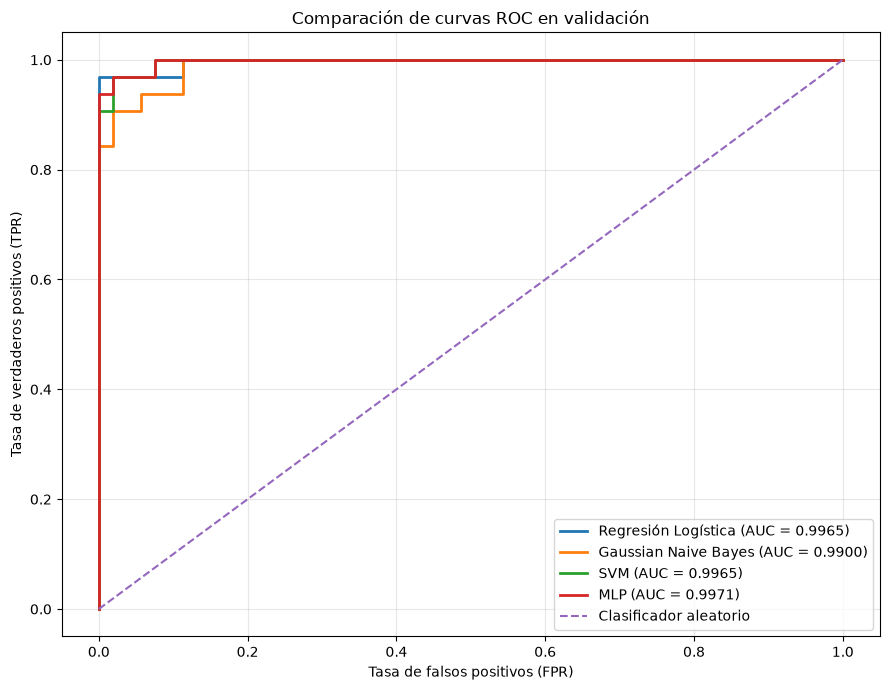

In [24]:
# ============================================================
# 26. COMPARACIÓN DE CURVAS ROC EN VALIDACIÓN
# ============================================================

# SVM utiliza decision_function porque fue entrenado con probability=False.
y_scores_logistic = baseline_model.predict_proba(X_val)[:, 1]
y_scores_nb = nb_model.predict_proba(X_val)[:, 1]
y_scores_svm = svm_model.decision_function(X_val)
y_scores_mlp = mlp_model.predict_proba(X_val)[:, 1]

modelos_scores_validacion = {
    "Regresión Logística": y_scores_logistic,
    "Gaussian Naive Bayes": y_scores_nb,
    "SVM": y_scores_svm,
    "MLP": y_scores_mlp
}

plt.figure(figsize=(9, 7))
for nombre, scores in modelos_scores_validacion.items():
    fpr, tpr, _ = roc_curve(y_val, scores)
    valor_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, linewidth=2, label=f"{nombre} (AUC = {valor_auc:.4f})")

plt.plot([0, 1], [0, 1], linestyle="--", label="Clasificador aleatorio")
plt.xlabel("Tasa de falsos positivos (FPR)")
plt.ylabel("Tasa de verdaderos positivos (TPR)")
plt.title("Comparación de curvas ROC en validación")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "figura_4_comparacion_curvas_roc.png", dpi=300, bbox_inches="tight")
plt.show()


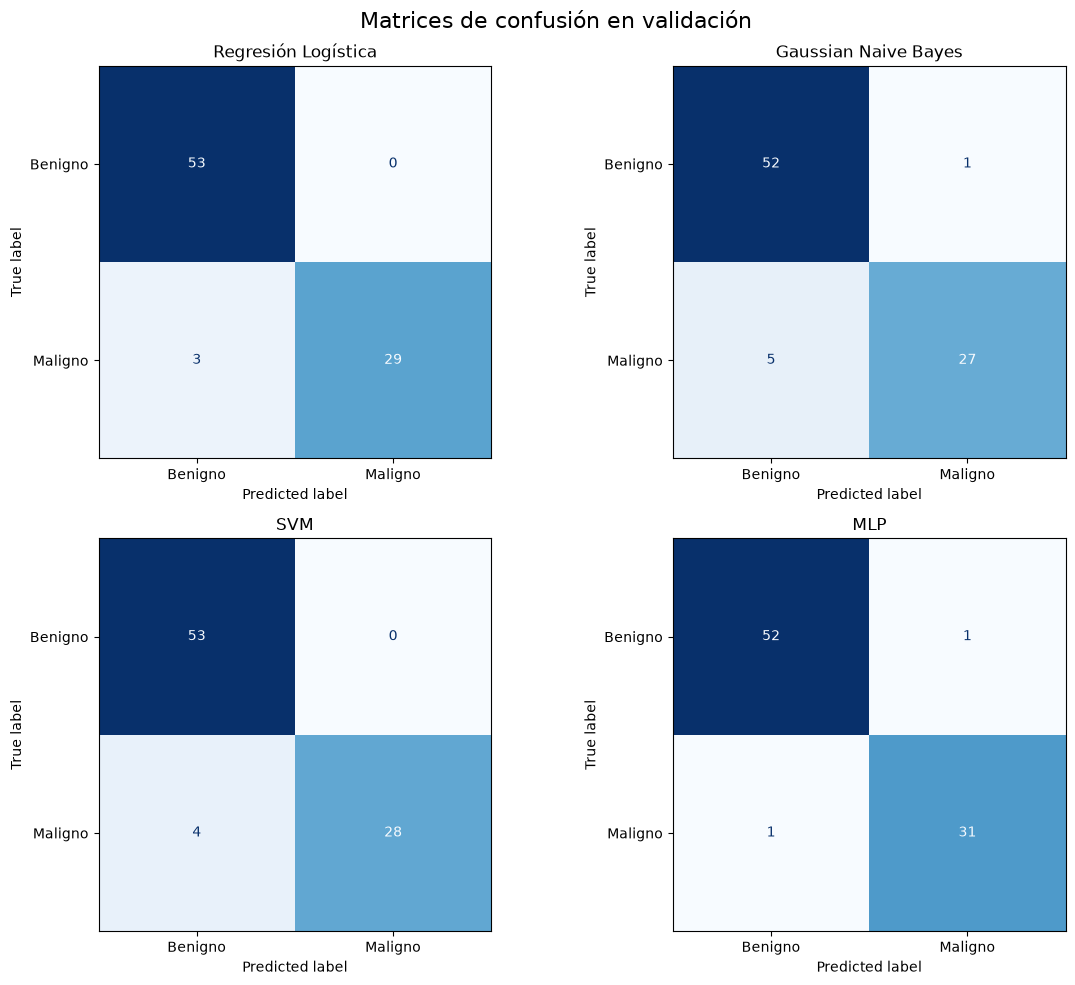

In [25]:
# ============================================================
# 27. COMPARACIÓN DE MATRICES DE CONFUSIÓN EN VALIDACIÓN
# ============================================================

modelos_predicciones = {
    "Regresión Logística": baseline_model.predict(X_val),
    "Gaussian Naive Bayes": nb_model.predict(X_val),
    "SVM": svm_model.predict(X_val),
    "MLP": mlp_model.predict(X_val)
}

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
for ax, (nombre, predicciones) in zip(axes.flatten(), modelos_predicciones.items()):
    matriz = confusion_matrix(y_val, predicciones)
    cm_display = ConfusionMatrixDisplay(
        confusion_matrix=matriz,
        display_labels=["Benigno", "Maligno"]
    )
    cm_display.plot(ax=ax, cmap="Blues", values_format="d", colorbar=False)
    ax.set_title(nombre)

plt.suptitle("Matrices de confusión en validación", fontsize=16)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "figura_5_matrices_confusion.png", dpi=300, bbox_inches="tight")
plt.show()


### Comparación global de modelos


In [26]:
# ============================================================
# 28. COMPARACIÓN GLOBAL DE VALIDACIÓN CRUZADA
# ============================================================

metricas_cv = ["accuracy", "precision", "recall", "f1", "roc_auc"]
fuentes_cv = {
    "Regresión Logística": (cv_results, None),
    "Gaussian Naive Bayes": (nb_search.cv_results_, nb_search.best_index_),
    "SVM": (svm_search.cv_results_, svm_search.best_index_),
    "MLP": (mlp_search.cv_results_, mlp_search.best_index_)
}

filas = []
for nombre, (resultados, mejor_indice) in fuentes_cv.items():
    fila = {"Modelo": nombre}
    for metrica in metricas_cv:
        if mejor_indice is None:
            valores = resultados[f"test_{metrica}"]
            media = valores.mean()
            desviacion = valores.std()
        else:
            media = resultados[f"mean_test_{metrica}"][mejor_indice]
            desviacion = resultados[f"std_test_{metrica}"][mejor_indice]
        fila[f"{metrica.upper()}_media"] = media
        fila[f"{metrica.upper()}_std"] = desviacion
    filas.append(fila)

comparacion = pd.DataFrame(filas)
comparacion_visual = comparacion.copy()
columnas_metricas = [c for c in comparacion_visual.columns if c != "Modelo"]
comparacion_visual[columnas_metricas] *= 100

mostrar_tabla(comparacion_visual.style.format({c: "{:.2f}%" for c in columnas_metricas}))
comparacion.to_csv(REPORTS_DIR / "comparacion_modelos_validacion_cruzada.csv", index=False)
print("Comparación de validación cruzada guardada en:", REPORTS_DIR)


AttributeError: The '.style' accessor requires jinja2

### Guardado de modelos entrenados

In [ ]:
# ============================================================
# 30. CONSOLIDAR LOS MODELOS AJUSTADOS
# ============================================================

# Los mejores estimadores de GridSearchCV ya fueron reajustados
# automáticamente con X_train al terminar cada búsqueda (refit="f1").
# La regresión logística se ajustó con X_train en la sección de referencia.
modelos_entrenados = {
    "Regresión Logística": baseline_model,
    "Gaussian Naive Bayes": nb_model,
    "SVM": svm_model,
    "MLP": mlp_model
}

print("Los cuatro modelos están preparados para la evaluación final.")


### Evaluación final con el conjunto de prueba

In [ ]:
# ============================================================
# 32. EVALUACIÓN FINAL EN EL CONJUNTO DE PRUEBA
# ============================================================

resultados_test = []
matrices_test = {}

for nombre, modelo in modelos_entrenados.items():
    y_pred = modelo.predict(X_test)
    clasificador = modelo.named_steps.get("classifier", modelo)

    if hasattr(clasificador, "predict_proba") and bool(getattr(clasificador, "probability", True)):
        y_score = modelo.predict_proba(X_test)[:, 1]
    else:
        y_score = modelo.decision_function(X_test)

    matriz = confusion_matrix(y_test, y_pred)
    matrices_test[nombre] = matriz

    resultados_test.append({
        "Modelo": nombre,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1": f1_score(y_test, y_pred, zero_division=0),
        "ROC_AUC": roc_auc_score(y_test, y_score),
        "Average_Precision": average_precision_score(y_test, y_score)
    })

tabla_test = pd.DataFrame(resultados_test)
print("COMPARACIÓN FINAL EN CONJUNTO DE PRUEBA")
mostrar_tabla(tabla_test.round(4))

print("\nMATRICES DE CONFUSIÓN")
for nombre, matriz in matrices_test.items():
    print(f"\n{nombre}")
    print(matriz)

tabla_test.to_csv(REPORTS_DIR / "resultados_evaluacion_test.csv", index=False)
print("\nResultados guardados correctamente en:", REPORTS_DIR)


In [ ]:
# ============================================================
# 33. GUARDADO DEFINITIVO DE LOS MODELOS EVALUADOS
# ============================================================

modelos_finales = {
    "regresion_logistica": baseline_model,
    "gaussian_naive_bayes": nb_model,
    "svm": svm_model,
    "mlp": mlp_model
}

for nombre, modelo in modelos_finales.items():
    ruta = MODELS_DIR / f"{nombre}.joblib"
    joblib.dump(modelo, ruta)
    print(f"Modelo guardado: {ruta}")

print("\nLos cuatro modelos evaluados fueron guardados correctamente.")


In [ ]:
# ============================================================
# 34. VERIFICACIÓN DE RECUPERACIÓN DE LOS MODELOS
# ============================================================

modelos_cargados = {
    nombre: joblib.load(MODELS_DIR / f"{nombre}.joblib")
    for nombre in modelos_finales
}

for nombre, modelo_original in modelos_finales.items():
    pred_original = modelo_original.predict(X_val)
    pred_cargado = modelos_cargados[nombre].predict(X_val)
    correcto = np.array_equal(pred_original, pred_cargado)
    print(f"{nombre}: {'Correcto' if correcto else 'Error'}")
    if not correcto:
        raise AssertionError(f"Error al recuperar el modelo {nombre}")

print("\nVerificación de recuperación completada.")


### 35. Curvas Precision-Recall en el conjunto de prueba

Se muestran como análisis complementario. Para SVM se usa la función de decisión, ya que el clasificador se entrenó sin estimación de probabilidades.

In [ ]:
# ============================================================
# 35. CURVAS PRECISION-RECALL EN EL CONJUNTO DE PRUEBA
# ============================================================

scores_test = {}
resultados_pr = []

for nombre, modelo in modelos_entrenados.items():
    clasificador = modelo.named_steps.get("classifier", modelo)
    if hasattr(clasificador, "predict_proba") and bool(getattr(clasificador, "probability", True)):
        scores = modelo.predict_proba(X_test)[:, 1]
    else:
        scores = modelo.decision_function(X_test)

    scores_test[nombre] = scores
    ap = average_precision_score(y_test, scores)
    resultados_pr.append({"Modelo": nombre, "Average_Precision": ap})

plt.figure(figsize=(8.6, 6.4))
for nombre, scores in scores_test.items():
    precision, recall, _ = precision_recall_curve(y_test, scores)
    ap = average_precision_score(y_test, scores)
    plt.step(recall, precision, where="post", linewidth=2,
             label=f"{nombre} (AP = {ap:.4f})")

prevalencia = y_test.mean()
plt.axhline(prevalencia, linestyle="--", linewidth=1.5,
            label=f"Referencia (prevalencia = {prevalencia:.3f})")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Curvas Precision-Recall en el conjunto de prueba")
plt.xlim(0, 1.01)
plt.ylim(0, 1.04)
plt.grid(alpha=0.25)
plt.legend(loc="lower left", fontsize=8)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "figura_6_precision_recall_test.png", dpi=300, bbox_inches="tight")
plt.show()

resultados_pr_df = pd.DataFrame(resultados_pr)
mostrar_tabla(resultados_pr_df.round(4))
resultados_pr_df.to_csv(REPORTS_DIR / "resultados_precision_recall.csv", index=False)
print("Curva y métricas Precision-Recall guardadas correctamente.")


### 36. Análisis de errores en el conjunto de prueba

Se identifican los registros incorrectamente clasificados, conservando sus identificadores como metadatos (no como predictores). Los valores de las características sirven para describir casos, no para atribuir causalidad a los errores.

In [ ]:
# ============================================================
# 36. ANÁLISIS DE ERRORES EN EL CONJUNTO DE PRUEBA
# ============================================================

# Cargar metadatos del test; ID no forma parte de X_test ni del entrenamiento.
test_metadata = pd.read_csv(PROCESSED_DATA_DIR / "test_metadata.csv")
labels_metadata = test_metadata["Diagnosis"].map({"B": 0, "M": 1})
if not np.array_equal(labels_metadata.to_numpy(), y_test.to_numpy()):
    raise ValueError("Los metadatos no corresponden al orden de y_test.")

variables_revision = [
    "radius1", "perimeter1", "area1", "concavity1", "concave_points1"
]
variables_revision = [c for c in variables_revision if c in X_test.columns]

filas_errores = []
filas_resumen = []

for nombre, modelo in modelos_entrenados.items():
    predicciones = modelo.predict(X_test)
    indices_error = np.flatnonzero(predicciones != y_test.to_numpy())
    falsos_positivos = 0
    falsos_negativos = 0

    for indice in indices_error:
        real = int(y_test.iloc[indice])
        predicho = int(predicciones[indice])
        tipo_error = "Falso negativo" if real == 1 and predicho == 0 else "Falso positivo"
        if tipo_error == "Falso negativo":
            falsos_negativos += 1
        else:
            falsos_positivos += 1

        fila = {
            "Modelo": nombre,
            "ID": int(test_metadata.iloc[indice]["ID"]),
            "Diagnostico_real": "Maligno" if real == 1 else "Benigno",
            "Diagnostico_predicho": "Maligno" if predicho == 1 else "Benigno",
            "Tipo_error": tipo_error
        }
        for variable in variables_revision:
            fila[variable] = float(X_test.iloc[indice][variable])
        filas_errores.append(fila)

    filas_resumen.append({
        "Modelo": nombre,
        "Falsos_positivos": falsos_positivos,
        "Falsos_negativos": falsos_negativos,
        "Total_errores": len(indices_error)
    })

resumen_errores = pd.DataFrame(filas_resumen)
detalle_errores = pd.DataFrame(
    filas_errores,
    columns=["Modelo", "ID", "Diagnostico_real", "Diagnostico_predicho", "Tipo_error"] + variables_revision
)

print("RESUMEN DE ERRORES")
mostrar_tabla(resumen_errores)
print("\nREGISTROS MAL CLASIFICADOS")
if detalle_errores.empty:
    print("Ningún modelo presentó errores en el conjunto de prueba.")
else:
    mostrar_tabla(detalle_errores)

resumen_errores.to_csv(REPORTS_DIR / "resumen_errores_test.csv", index=False)
detalle_errores.to_csv(REPORTS_DIR / "analisis_errores_test.csv", index=False)
print("\nAnálisis de errores guardado en:", REPORTS_DIR)


### 37. Matrices de confusión del conjunto de prueba

In [ ]:
# ============================================================
# 37. MATRICES DE CONFUSIÓN DEL CONJUNTO DE PRUEBA
# ============================================================

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
for ax, (nombre, modelo) in zip(axes.flatten(), modelos_entrenados.items()):
    predicciones = modelo.predict(X_test)
    matriz = confusion_matrix(y_test, predicciones)
    cm_display = ConfusionMatrixDisplay(
        confusion_matrix=matriz,
        display_labels=["Benigno", "Maligno"]
    )
    cm_display.plot(ax=ax, cmap="Blues", values_format="d", colorbar=False)
    ax.set_title(nombre)

plt.suptitle("Matrices de confusión en el conjunto de prueba", fontsize=16)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "figura_7_matrices_confusion_test.png", dpi=300, bbox_inches="tight")
plt.show()
